# Projet ML kaggle : Give me some credits

## Prédiction du risque de défaut de paiement par apprentissage automatique

* #### L'évaluation du risque de crédit est un enjeu majeur pour les banques. Avant d'accorder un prêt, les banques doivent s'assurer que leur client va pouvoir rembourser le prêt sans retard avant sous deux ans. Pour étudier la capacité de l'emprunteur à rembourser son prêt dans les temps, on établit un modèle prédictif qui prend en compte nombre de ses caractéristiques économiques. 
#### En effet, un modèle qui estime avec trop grand laxisme peut entraîner des pertes économiques, mais une évaluation trop restrictive pourrait conduire à refuser des crédits à des clients solvables.

* #### L'objectif consiste donc à prédire la variable binaire **SeriousDlqin2yrs**, qui indique si un emprunteur connaîtra un retard de paiement d'au moins 90 jours au cours des deux années suivantes.

* #### On se demandera donc dans quelle mesure les méthodes de machine learning permettent-elles d'identifier les emprunteurs présentant un risque de défaut de paiement, malgré un fort déséquilibre des classes, et comment améliorer leurs performances grâce au prétraitement des données, au feature engineering et à l'optimisation des modèles.

## SOMMAIRE :

##### 1. Préparation des données
##### 2. Exploration des données et analyse de leurs caractéristiques
##### 3. Première baseline naïve
##### 4. Nettoyage des données et deuxième baseline naïve
##### 5. Comparaison des algorithmes
##### 6. Feature ingineering supplémentaire
##### 7. Optimisation du XG Boost
##### 8. Evaluation du modèle
##### 9. Discussions et limites

## 1. Préparation des données
### 1.A Import des modules

In [1]:
# Imports des modules nécessaires

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split

### 1.B Import des données

In [148]:
# Imports du jeu de données cs-training.csv
df = pd.read_csv("cs-training.csv", index_col=0)
print("Taille du jeu de données :", df.shape)

# On regarde la proportion respectivement de 0 et 1 dans la colonne cible SeriousDlqin2yrs
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))
df.head(10)

Taille du jeu de données : (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
6,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
8,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
9,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
10,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


##### On remarque déjà que les données de la variable cible sont très déséquilibrées (93% de non retards contre 7% de retards environs)

### 1.C Préparation des des données d'entraînement et de test

In [149]:
# Découpage du jeu de données cs-training.csv en un jeu d'entraînement et un jeu de test

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=13)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
0.06684166666666666 0.06683333333333333


## 2. Exploration des données et analyse de leurs caractéristiques
### 2.A Description générale du jeu de données train

In [68]:
train = X_train.copy()
train["SeriousDlqin2yrs"] = y_train

print("\nStructure des données de train : \n------------------")
train.info()                    # On repère notamment les valeurs manquantes et le type des variables
print("\nQuelques statistiques descriptives : \n------------------")
train.describe().T


Structure des données de train : 
------------------
<class 'pandas.core.frame.DataFrame'>
Index: 120000 entries, 146439 to 92061
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 1   age                                   120000 non-null  int64  
 2   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 3   DebtRatio                             120000 non-null  float64
 4   MonthlyIncome                         96225 non-null   float64
 5   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 6   NumberOfTimes90DaysLate               120000 non-null  int64  
 7   NumberRealEstateLoansOrLines          120000 non-null  int64  
 8   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 9   NumberOfDependents                    116877 non-null  float64
 10  SeriousDlqin2yr

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,120000.0,5.929586,257.068219,0.0,0.029979,0.153984,0.558550,50708.0
age,120000.0,52.306758,14.776183,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.423042,4.219454,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,355.473945,2185.289400,0.0,0.174769,0.366735,0.870933,329664.0
MonthlyIncome,96225.0,6629.724365,12002.494899,0.0,3400.000000,5400.000000,8210.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.441208,5.144652,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.268392,4.195798,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.015817,1.128004,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.242983,4.182032,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,116877.0,0.755469,1.113718,0.0,0.000000,0.000000,1.000000,20.0


* ##### Deuxième remarque : les manquants dans deux variables notamment : MonthlyIncome et NumberOfDependents
* ##### On a aussi des moyennes aberrantes comme pour DebtRatio et des maximum suspects pour le nombre de fois où le retard a déjà dépassé 30/60 ou 90 jours par le passé
Regardons ces anomalies de plus près dans la suite

### 2.B Description des valeurs manquantes

In [150]:
print("\nProportion de valeurs manquantes dans chaque variable du jeu de données train : \n------------------")
missing = train.isna().mean().sort_values(ascending=False) * 100
print(missing[missing > 0].round(2))

# On regarde la proportion de défauts de paiement en fonction des variables avec valeurs manquantes
print("\nLes manquants sont-ils corrélés avec la variable cible ? \n------------------")
for i in ["MonthlyIncome", "NumberOfDependents"]:
    taux = train.groupby(train[i].isna())["SeriousDlqin2yrs"].mean()
    print(i, "\n", taux.rename({False: "renseigné", True: "manquant"}), "\n")



Proportion de valeurs manquantes dans chaque variable du jeu de données train : 
------------------
MonthlyIncome         19.81
NumberOfDependents     2.60
dtype: float64

Les manquants sont-ils corrélés avec la variable cible ? 
------------------
MonthlyIncome 
 MonthlyIncome
renseigné    0.069410
manquant     0.056446
Name: SeriousDlqin2yrs, dtype: float64 

NumberOfDependents 
 NumberOfDependents
renseigné    0.067421
manquant     0.045149
Name: SeriousDlqin2yrs, dtype: float64 



* ##### Ce qu'on observe : 2 variables contiennent des valeurs manquantes

    - Près de 20% des personnes n'ont pas renseigné leur revenu mensuel (MonthlyIncome)
    - On a 2,6% de valeurs manquantes sur le nombre de personnes à charge (NumberOfDependents)

* ##### Comment interpréter les valeurs manquantes ?

On calcule le taux de défaut de paiement dans chaque groupe qui contient des manquants.
On remarque cependant qu'on ne peut pas conclure sur l'association entre l'absence de revenus indiquée et un potentiel défaut de paiement, de même pour le NumberOfDependents.

* ##### Comment gérer les valeurs manquantes dans la suite?

On aurait pu supprimer les lignes de valeurs manquantes, mais elles représentent près de 20% des données pour MonthlyIncome notamment, et il paraît plus judicieux de les remplacer par la médiane lors du nettoyage des données.

### 2.C Analyse des valeurs suspectes

In [71]:
print("Âge < 18 ans :", (train["age"] <18 ).sum())
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    valeurs = train[train[col] > 1][col]
    print(col, "/ nombre :", len(valeurs), "/ moyenne :", round(valeurs.mean(), 2), "/ médiane :", round(valeurs.median(), 2))

retards = ["NumberOfTime30-59DaysPastDueNotWorse",
           "NumberOfTimes90DaysLate",
           "NumberOfTime60-89DaysPastDueNotWorse"]
for c in retards:
    print(c, train[c].value_counts().sort_index().tail(6).to_dict())

print("Doublons :", train.duplicated().sum())

Âge < 18 ans : 1
RevolvingUtilizationOfUnsecuredLines / nombre : 2656 / moyenne : 254.49 / médiane : 1.07
DebtRatio / nombre : 28159 / moyenne : 1513.87 / médiane : 900.0
NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 2, 13: 1, 96: 4, 98: 214}
NumberOfTimes90DaysLate {13: 4, 14: 2, 15: 2, 17: 1, 96: 4, 98: 214}
NumberOfTime60-89DaysPastDueNotWorse {7: 7, 8: 1, 9: 1, 11: 1, 96: 4, 98: 214}
Doublons : 419


* ##### Ce qu'on observe : certaines données qui attirent l'attention
    - Des clients qui seraient mineurs : cela pourrait être soit une erreur de saisie, soit une donnée manquante pour l'âge remplacée par un 0

    - **Le ratio d'utilisation de crédit > 1** : n'est pas alarmant en soi, mais pourrait être un indicateur pour l'interprétation des résultats plus tard. On remarque des données aberrantes avec une moyenne 265 fois supérieure à la médiane, donc tirée par ces valeurs hors normes.

    - **Le ratio de dette > 1** : n'est pas non plus alarmant en soi que le ratio puisse être supérieur à 1, mais comme ce ratio dépend du revenu mensuel pour lequel on a beaucoup de données manquantes (20%), il faut rester vigilant aux erreurs de calcul. Ici ce n'est pas une anomalie rare car plus de 27000 lignes la contiennent, soit presque 20% du nombre de lignes tout comme le nombre de données manquantes en MonthlyIncome : on a donc probablement des aberrations sur le ratio de dettes à cause des données manquantes de MonthlyIncome ou des MonthlyIncome = 0.

* ##### Les retards de paiement
    - Concernant les retards : certains chiffres très élevés comme 96 ou 98 apparaissant près de 214 fois par variables peuvent représenter des anomalies de saisie ou de calcul, ou bien codes à déchiffrer lors de l'apprentissage. Il est assez surprenant d'avoir un client ayant dépassé 96 ou 98 fois les 30 jours de retards de paiement en 2 ans.

* ##### Les doublons
    - On a 437 doublons qui peuvent fausser les données. Cependant plusieurs clients peuvent avoir les mêmes lignes descriptives.

### 2.D Etude des distributions graphiques des données

##### Visualisons maintenant de plus près ce que donne la distribution de nos données

- ### Répartition de la variable cible

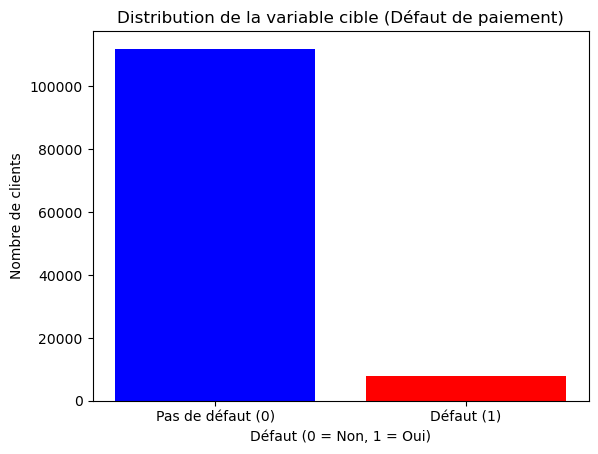

In [151]:
# Calcul manuel des hauteurs des barres
nb_total = len(train["SeriousDlqin2yrs"])
nb_defauts = train["SeriousDlqin2yrs"].sum()
nb_bons = nb_total - nb_defauts

# On trace le graphique en passant directement les positions [0, 1] et les hauteurs [nb_bons, nb_defauts]
plt.bar([0, 1], [nb_bons, nb_defauts], color=['blue', 'red'])
plt.title("Distribution de la variable cible (Défaut de paiement)")
plt.xlabel("Défaut (0 = Non, 1 = Oui)")
plt.ylabel("Nombre de clients")
plt.xticks([0, 1], ["Pas de défaut (0)", "Défaut (1)"])
plt.show()

- ### Comment se répartissent les données pour chaque variable explicative ?

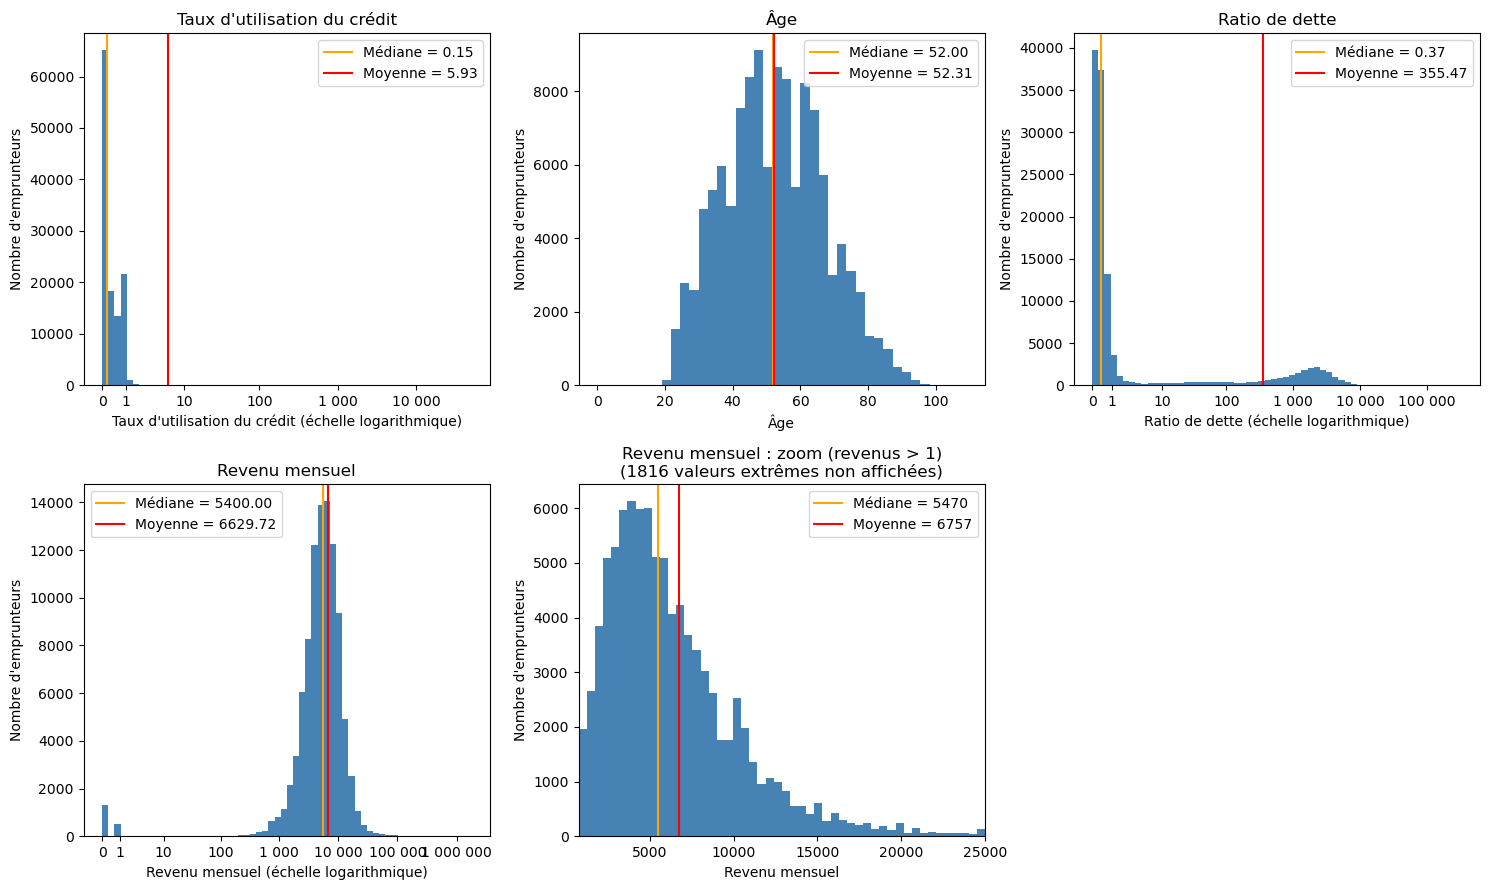

In [152]:
variables = {
    "RevolvingUtilizationOfUnsecuredLines": "Taux d'utilisation du crédit",
    "age": "Âge",
    "DebtRatio": "Ratio de dette",
    "MonthlyIncome": "Revenu mensuel",
}

variables_log = {"RevolvingUtilizationOfUnsecuredLines","DebtRatio","MonthlyIncome"}

ticks_reels = [0, 1, 10, 100, 1000, 10000, 100000, 1000000]


def regler_axe_log(ax, valeurs, nom):
    """Affiche un axe en log1p mais avec des graduations en valeurs réelles."""
    ticks = [t for t in ticks_reels if t <= valeurs.max()]
    ax.set_xticks(np.log1p(ticks))
    ax.set_xticklabels([f"{t:,}".replace(",", " ") for t in ticks])
    ax.set_xlabel(f"{nom} (échelle logarithmique)")


def tracer_histogramme(ax, serie, nom, log=False, bins=50):
    """Trace un histogramme avec moyenne et médiane."""
    valeurs = serie.dropna()

    moyenne = valeurs.mean()
    mediane = valeurs.median()

    if log:
        valeurs_tracees = np.log1p(valeurs)
        pos_moyenne = np.log1p(moyenne)
        pos_mediane = np.log1p(mediane)

        ax.hist(valeurs_tracees, bins=bins, color="steelblue")
        regler_axe_log(ax, valeurs, nom)
    else:
        valeurs_tracees = valeurs
        pos_moyenne = moyenne
        pos_mediane = mediane

        ax.hist(valeurs_tracees, bins=bins, color="steelblue")
        ax.set_xlabel(nom)

    ax.axvline(pos_mediane, color="orange", label=f"Médiane = {mediane:.2f}")
    ax.axvline(pos_moyenne, color="red", label=f"Moyenne = {moyenne:.2f}")
    ax.set_title(nom)
    ax.set_ylabel("Nombre d'emprunteurs")
    ax.legend()


def tracer_zoom_revenu(ax, serie):
    """Trace un zoom du revenu mensuel en échelle normale."""
    revenus = serie.dropna()
    revenus = revenus[revenus > 1]  # on retire 0 et 1

    moyenne = revenus.mean()
    mediane = revenus.median()

    bas = revenus.quantile(0.01)
    haut = revenus.quantile(0.99)
    nb_exclus = ((revenus < bas) | (revenus > haut)).sum()

    ax.hist(revenus, bins=50, range=(bas, haut), color="steelblue")
    ax.axvline(mediane, color="orange", label=f"Médiane = {mediane:.0f}")
    ax.axvline(moyenne, color="red", label=f"Moyenne = {moyenne:.0f}")

    ax.set_xlim(bas, haut)
    ax.set_title(
        f"Revenu mensuel : zoom (revenus > 1)\n"
        f"({nb_exclus} valeurs extrêmes non affichées)")
    ax.set_xlabel("Revenu mensuel")
    ax.set_ylabel("Nombre d'emprunteurs")
    ax.legend()


# --- Figure ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

# 4 histogrammes principaux
for ax, (col, nom) in zip(axes[:4], variables.items()):
    tracer_histogramme(ax,train[col],nom,log=(col in variables_log),bins=60 if col in variables_log else 40)

# Zoom sur le revenu
tracer_zoom_revenu(axes[4], train["MonthlyIncome"])

# Dernière case vide
axes[5].axis("off")

plt.tight_layout()
plt.show()

* ##### Ce qu'on observe :

Pour chaque variable, on a tracé un histogramme (nombre d'emprunteurs par plage de valeurs),
avec la médiane (orange) et la moyenne (rouge). Le taux d'utilisation du crédit, le ratio de dette et le
revenu sont en échelle logarithmique (obligé sinon quelques valeurs énormes écraseraient tout le graphique)

* ##### Taux d'utilisation du crédit
  - La majorité des valeurs est entre 0 et 1 mais 2 640 lignes dépassent 1.
  - On peut penser qu'un taux légèrement supérieur à 1 est possible (dépassement de la limite), mais les valeurs énormes sont suspectes. Elles tirent la moyenne bien au-dessus de la médiane.

* ##### Âge
  - Une courbe en cloche qui paraît assez instinctive, on a une seule ligne avec age < 18.
  - C'est une variable propre, sans valeur extrême problématique. On mettre un Na sur la valeur par la suite.

* ##### Ratio de dette
  - On a 27 987 lignes qui ont un ratio supérieur à 1. C'est trop de lignes pour de simples erreurs. 
  - Hypothèse : le ratio devient énorme quand le revenu est manquant, 0 ou 1.
  - Dans un premier temps, on va supprimer les valeurs aberrantes de cette variable et les remplacer par la médiane. 
  - Cela pourrait cependant être intéressant de voir l'importance des aberrations dans l'explication de la variable cible et donc garder ces valeurs aberrantes dans un second temps.

* ##### Revenu mensuel
  - Médiane = 5 390, moyenne = 6 651. La majorité des emprunteurs se situe entre quelques milliers et 10 000. Deux petites barres isolées, à 0 et à 1.
  - On a un revenu de 1 par mois qui semble très suspect, probablement une erreur de remplissage. Le zoom (sans log, revenus > 1) montre une distribution asymétrique mais plutôt instinctive également.
  - On décide de traiter les revenus ≤ 1 comme manquants, et de remplacer les 19,7 % de manquants par la médiane de la variable. 
  - Une autre stratégie intéressante aurait été de garder le caractère manquant dans une nouvelle variable dans un  second temps.

##### Conclusion
Trois variables sont dominées par des valeurs extrêmes ou suspectes. On corrigera cela dans le pipeline
(étape 5), en apprenant les transformations sur le train seulement.

- ### Y a-t-il des corrélations entre les variables explicatives ? 

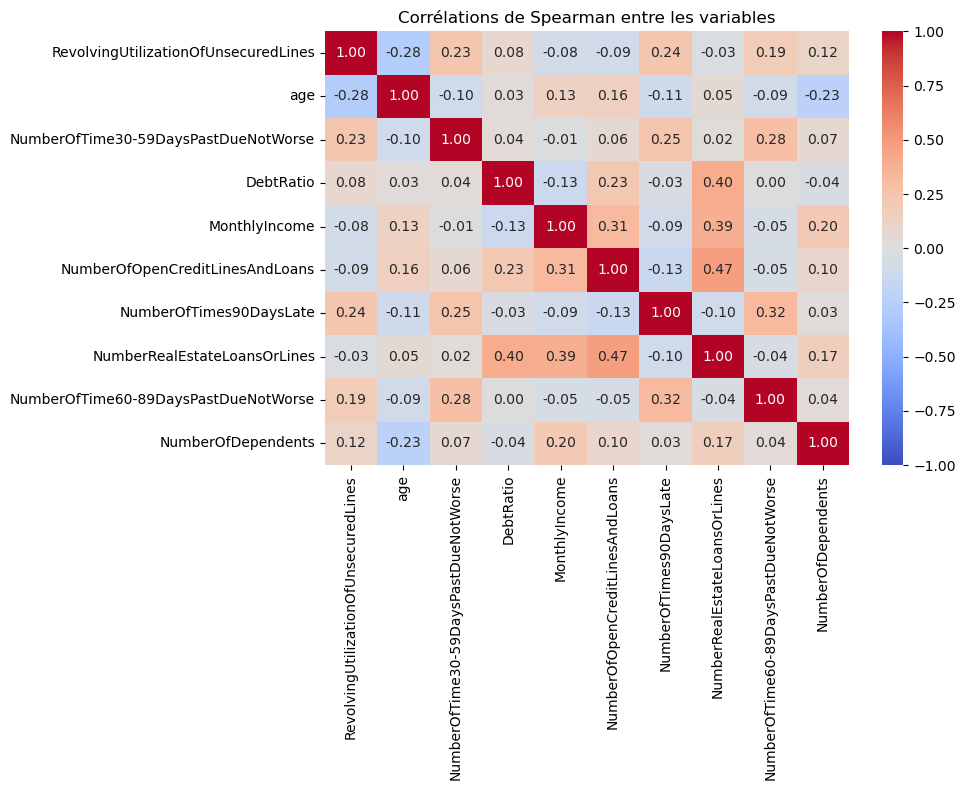

Les 5 paires de variables les plus corrélées :
NumberOfOpenCreditLinesAndLoans  NumberRealEstateLoansOrLines            0.47
DebtRatio                        NumberRealEstateLoansOrLines            0.40
MonthlyIncome                    NumberRealEstateLoansOrLines            0.39
NumberOfTimes90DaysLate          NumberOfTime60-89DaysPastDueNotWorse    0.32
MonthlyIncome                    NumberOfOpenCreditLinesAndLoans         0.31
dtype: float64


In [155]:
import seaborn as sns

# Corrélations sur les données d'entraînement uniquement
X_eda = train.drop(
    columns=["SeriousDlqin2yrs", "Unnamed: 0", "tranche_age"],
    errors="ignore"
)

correlations = X_eda.corr(method="spearman")

# Matrice de corrélation
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Corrélations de Spearman entre les variables")
plt.tight_layout()
plt.show()

# Les 5 paires les plus corrélées
paires = correlations.where(
    np.triu(np.ones(correlations.shape, dtype=bool), k=1)
).stack()

paires = paires.reindex(
    paires.abs().sort_values(ascending=False).index
)

print("Les 5 paires de variables les plus corrélées :")
print(paires.head(5).round(2))

#### Ce qu'on observe : Il n'y a pas de corrélations qui se dénotent dans notre jeu de données (chaque corrélation est inférieur au seuil de 0,7 : On ne pense donc pas à enlever une variable qui serait en trop.

- ### Quelles variables expliquent le mieux la variable cible?

In [154]:
from sklearn.metrics import roc_auc_score

force = {}
for col in X.columns:
    score = X[col].fillna(X[col].median())       # les manquants sont remplacés par la médiane, pour ce calcul seulement
    auc = roc_auc_score(y, score)
    force[col] = max(auc, 1 - auc)               # si auc < 0.5, la variable agit en sens inverse : on la retourne

print(pd.Series(force).sort_values(ascending=False).round(3))

RevolvingUtilizationOfUnsecuredLines    0.778
NumberOfTime30-59DaysPastDueNotWorse    0.690
NumberOfTimes90DaysLate                 0.657
age                                     0.635
NumberOfTime60-89DaysPastDueNotWorse    0.622
MonthlyIncome                           0.571
NumberOfDependents                      0.548
NumberOfOpenCreditLinesAndLoans         0.545
NumberRealEstateLoansOrLines            0.537
DebtRatio                               0.524
dtype: float64


#### Ce qu'on observe : Avant le nettoyage des données, nous avons : 
* #### RevolvingUtilizationOfUnsecuredLines qui explique le mieux la variable cible jusqu'ici : c'est le taux d'utilisation du crédit ce qui peut traduire : un taux d'utilisation élevé peut être associé à une plus grande vulnérabilité financière. On aurait : 

    - Une dépendance importante au crédit pour financer ses dépenses.
    - Une marge de manoeuvre financière plus réduite en cas de dépense imprévue ou de baisse de salaire.

* #### Les retards de paiement sur plus de 30 / 60 ou 90 jours : ce sont des incidents de paiement déjà survenus, il paraît donc logique qu'il historique de retard de paiement non nul puisse affecter un potentiel retard de paiement plus tard. Tout comme la variable précédente, l'augmentation du nombre de retard de paiement est associé à une fragilité financière.

* #### Le DebtRatio est la variable la moins explicative de toutes, pourtant logiquement elle devrait l'être plus, on verra cela à nouveau après le nettoyage des données.

## 3. Première baseline naïve

### 3.A Importation de tous les modèles et les métriques dont nous aurons besoin dans la suite

In [190]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

# Validation croisée
validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Métriques
metriques = ["accuracy","roc_auc","average_precision","f1"]

# Modèles
modeles = {
    "Dummy": DummyClassifier(strategy="most_frequent"),

    "Régression logistique": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=4
    )
}

### 3.B Premiers modèles simples sans nettoyage pour constituer un témoin de comparaison avec la suite

In [157]:
# Suppression des deux colonnes techniques : l'identifiant et la colonne de tranches d'âge
X_brut = train.drop(columns=["SeriousDlqin2yrs", "Unnamed: 0", "tranche_age"], errors="ignore")
y_brut = train["SeriousDlqin2yrs"]

# Choix des modèles naïfs de base
modeles_brut = {
    "Modèle naïf": modeles["Dummy"],
    "Régression logistique simple": modeles["Régression logistique"]
}

resultats_brut = {}
for nom, modele in modeles_brut.items():
    scores = cross_validate(modele, X_brut, y_brut, cv=validation, scoring=metriques)
    resultats_brut[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats_brut).T.round(3))

                              accuracy  roc_auc  average_precision     f1
Modèle naïf                      0.933    0.500              0.067  0.000
Régression logistique simple     0.934    0.697              0.230  0.072


## 4. Nettoyage des données et deuxième baseline naïve

### 4.A Nettoyage des données : on remplace les données aberrantes par des données manquantes

In [167]:
def nettoyer(df):
    df = df.copy()                                           

    colonnes_retards = ["NumberOfTime30-59DaysPastDueNotWorse",
                        "NumberOfTime60-89DaysPastDueNotWorse",
                        "NumberOfTimes90DaysLate"]
    for col in colonnes_retards:
        df.loc[df[col] >= 96, col] = np.nan                       # On enlève les codes 96 et 98 qui sont des valeurs spéciales

    df.loc[df["MonthlyIncome"] <= 1, "MonthlyIncome"] = np.nan   # On enlève les revenus de 0 ou 1
    df.loc[df["MonthlyIncome"].isna(), "DebtRatio"] = np.nan     # Sans revenu fiable, le ratio de dette n'a pas de sens
    df.loc[df["age"] < 18, "age"] = np.nan                         # On enlève les mineurs de la catégorie d'âge

    return df.drop(columns=["Unnamed: 0", "tranche_age"], errors="ignore")   # on retire l'identifiant et la colonne de tranches d'âge


train_propre = nettoyer(train)

# Vérifications
print("Les manquants dans le jeu de données nettoyé :\n")
print(train_propre.isna().sum())

avant = train["DebtRatio"]
apres = train_propre["DebtRatio"]

print("\nLe ratio de dette avant et après nettoyage :")
print(f"\nDebtRatio avant : moyenne = {avant.mean():.2f}, médiane = {avant.median():.2f}, lignes > 1 : {(avant > 1).sum()}")
print(f"DebtRatio après : moyenne = {apres.mean():.2f}, médiane = {apres.median():.2f}, lignes > 1 : {(apres > 1).sum()}")

Les manquants dans le jeu de données nettoyé :

RevolvingUtilizationOfUnsecuredLines        0
age                                         1
NumberOfTime30-59DaysPastDueNotWorse      218
DebtRatio                               25590
MonthlyIncome                           25590
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                   218
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse      218
NumberOfDependents                       3123
SeriousDlqin2yrs                            0
dtype: int64

Le ratio de dette avant et après nettoyage :

DebtRatio avant : moyenne = 355.47, médiane = 0.37, lignes > 1 : 28159
DebtRatio après : moyenne = 0.41, médiane = 0.29, lignes > 1 : 4147


### 4.B On utilise le modèle naïf et la régression logistique sur les données désormais nettoyées

In [168]:
X = train_propre.drop(columns=["SeriousDlqin2yrs"])     # les variables
y = train_propre["SeriousDlqin2yrs"]                    # la cible (défaut ou non)

modeles_avec_nettoyage = {
    "Modèle naïf": modeles["Dummy"],
    "Régression logistique simple": modeles["Régression logistique"]
}

resultats = {}
for nom, modele in modeles_avec_nettoyage.items():
    scores = cross_validate(modele, X, y, cv=validation, scoring=metriques)
    resultats[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats).T.round(3))

                              accuracy  roc_auc  average_precision     f1
Modèle naïf                      0.933    0.500              0.067  0.000
Régression logistique simple     0.936    0.814              0.348  0.241


#### Ce qu'on observe : Les résultats sont meilleurs que pour la baseline sans nettoyage. On regarde principalement l'average_precision et on remarque qu'on est passés de 0.230 sans nettoyage à 0.348 après nettoyage, ce qui est encourageant.

### 4.C Matrice de confusion pour observer le rappel et la précision de la baseline

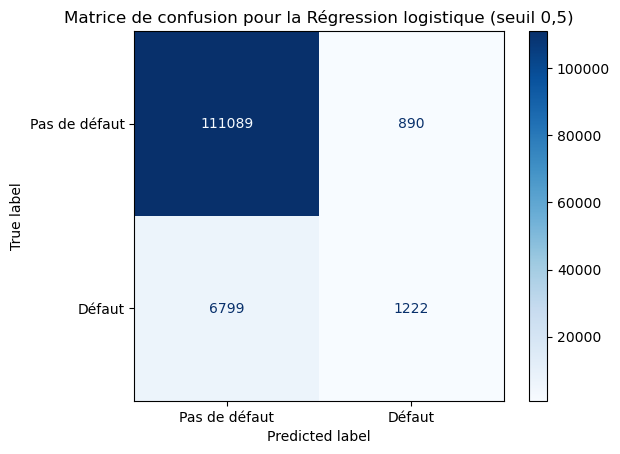

In [171]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

# Données nettoyées
X = train_propre.drop(columns=["SeriousDlqin2yrs"])
y = train_propre["SeriousDlqin2yrs"]

# Prédictions en validation croisée
probas = cross_val_predict(
    modeles["Régression logistique"],
    X,
    y,
    cv=validation,
    method="predict_proba"
)[:, 1]

# Classification avec un seuil de 0,5
predictions = (probas >= 0.5).astype(int)

# Matrice de confusion
ConfusionMatrixDisplay.from_predictions(
    y,
    predictions,
    display_labels=["Pas de défaut", "Défaut"],
    cmap="Blues"
)

plt.title("Matrice de confusion pour la Régression logistique (seuil 0,5)")
plt.show()

#### La matrice de confusion nous indique :

* #### Une précision de (1222/1222+890) = 57,9 % : donc parmis les individus que le modèle simple classe comme susceptibles de faire défaut, environ 58 % connaissent effectivement un défaut.

* #### Un rappel de (1222/1222+6799) = 15,2 % : donc parmis tous les individus qui connaissent réellement un défaut, le modèle n'en identifie que 15,2 %. Cela signifie donc qu'il manque près de 85 % des défauts réels.

### 4.D Les variables d'intérêt après nettoyage

In [169]:
from sklearn.metrics import roc_auc_score

force = {}
for col in X.columns:
    score = X[col].fillna(X[col].median())       # les manquants sont remplacés par la médiane, pour ce calcul seulement
    auc = roc_auc_score(y, score)
    force[col] = max(auc, 1 - auc)               # si auc < 0.5, la variable agit en sens inverse : on la retourne

print(pd.Series(force).sort_values(ascending=False).round(3))

RevolvingUtilizationOfUnsecuredLines    0.777
NumberOfTime30-59DaysPastDueNotWorse    0.679
NumberOfTimes90DaysLate                 0.650
age                                     0.635
NumberOfTime60-89DaysPastDueNotWorse    0.614
MonthlyIncome                           0.578
DebtRatio                               0.558
NumberOfOpenCreditLinesAndLoans         0.545
NumberOfDependents                      0.545
NumberRealEstateLoansOrLines            0.539
dtype: float64


#### On observe  que parmis les premières variables explicatives importantes, il n'y a pas eu tant de changement si ce n'est DebtRatio qui est remonté juste sous MonthlyIncome, sans être une variable prédominante pour autant.

## 5. Comparaison des algorithmes
#### On ajoute des modèles plus complexes : Random Forest et XG Boost

In [173]:
X = train_propre.drop(columns=["SeriousDlqin2yrs"])     # les variables
y = train_propre["SeriousDlqin2yrs"]                    # la cible (défaut ou non)

modeles_sans_features = {
    "Modèle naïf": modeles["Dummy"],
    "Régression logistique simple": modeles["Régression logistique"],
    "Forêt aléatoire": modeles["Random Forest"],
}

resultats = {}
for nom, modele in modeles_sans_features.items():
    scores = cross_validate(modele, X, y, cv=validation, scoring=metriques)
    resultats[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

# On rajoute le modèle XGBoost
scores = cross_validate(modeles["XGBoost"], X, y, cv=validation, scoring=metriques)
resultats["XGBoost"] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats).T.round(3))

                              accuracy  roc_auc  average_precision     f1
Modèle naïf                      0.933    0.500              0.067  0.000
Régression logistique simple     0.936    0.814              0.348  0.241
Forêt aléatoire                  0.935    0.833              0.342  0.266
XGBoost                          0.937    0.863              0.392  0.280


#### On observe une légère tendance à l'augmentation notamment au niveau de l'average_precision : le XG Boost est le modèle le plus performant jusqu'ici. Cependant, les performances restent limitées et la prédiction de la classe minoritaire reste difficile. Le compromis précision-rappel caractérisé par le F1-score reste également limité.
#### Dans la suite, on essaye de voir si le feature engineering influence les performances de nos modèles

## 6. Feature ingineering supplémentaire

### 6.A On crée une nouvelle variable TotalLatePayments qui est juste le cumul de tous les retards pour différentes durées

In [180]:
def ajouter_retards(df):
    df = df.copy()

    colonnes = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate"
    ]

    df["TotalLatePayments"] = df[colonnes].sum(axis=1, min_count=3)

    return df

* #### On crée deux versions avec et sans l'ajout de la nouvelle variable

In [181]:
# version 1 de base
V1 = train_propre.copy()
# version 2 avec les retards
V2 = ajouter_retards(V1)

datasets = {
    "V1 : Nettoyage simple": nettoyer(train),
    "V2 : Total des retards": ajouter_retards(nettoyer(train))
}


### 6.B Test avec le feature engineering

In [182]:
resultats = []

for nom_dataset, df in datasets.items():

    X = df.drop(columns=["SeriousDlqin2yrs"])
    y = df["SeriousDlqin2yrs"]

    for nom_modele, modele in modeles.items():

        scores = cross_validate(
            modele,
            X,
            y,
            cv=validation,
            scoring=metriques
        )

        resultats.append({
            "Dataset": nom_dataset,
            "Modèle": nom_modele,
            "Accuracy": scores["test_accuracy"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean(),
            "Average Precision": scores["test_average_precision"].mean()
        })

resultats_df = pd.DataFrame(resultats)

print(resultats_df.round(3))

                  Dataset                 Modèle  Accuracy  ROC-AUC  \
0   V1 : Nettoyage simple                  Dummy     0.933    0.500   
1   V1 : Nettoyage simple  Régression logistique     0.936    0.814   
2   V1 : Nettoyage simple          Random Forest     0.935    0.833   
3   V1 : Nettoyage simple                XGBoost     0.937    0.863   
4  V2 : Total des retards                  Dummy     0.933    0.500   
5  V2 : Total des retards  Régression logistique     0.936    0.814   
6  V2 : Total des retards          Random Forest     0.935    0.833   
7  V2 : Total des retards                XGBoost     0.937    0.863   

   Average Precision  
0              0.067  
1              0.348  
2              0.342  
3              0.392  
4              0.067  
5              0.348  
6              0.342  
7              0.394  


* #### On visualise avec plus de facilité

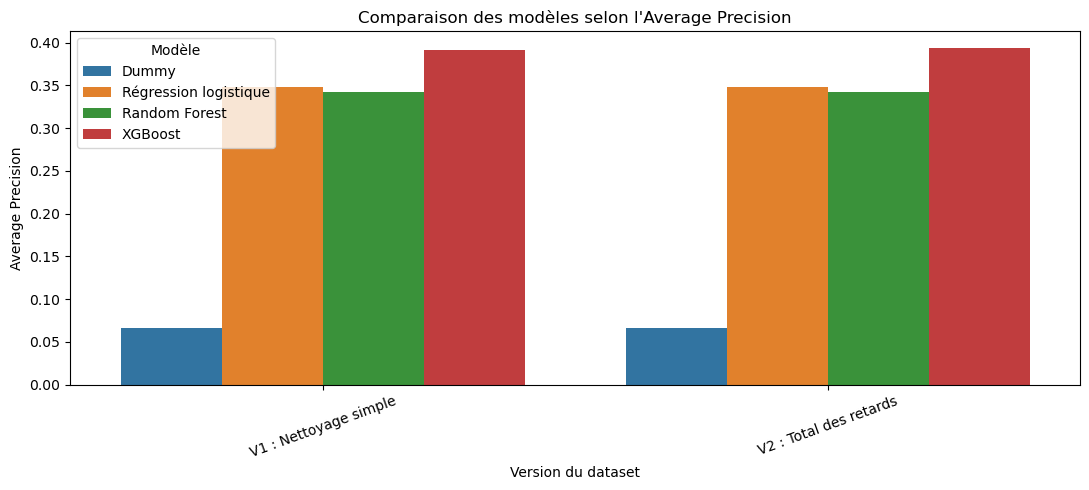

In [183]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

sns.barplot(
    data=resultats_df,
    x="Dataset",
    y="Average Precision",
    hue="Modèle"
)

plt.title("Comparaison des modèles selon l'Average Precision")
plt.xlabel("Version du dataset")
plt.ylabel("Average Precision")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### Finalement, on voit que le feature engineering qu'on a essayé a eu très peu d'impact sur la performance de nos modèles, avec une amélioration de seulement quelques millièmes par rapport aux modèles appliqués sur données simplement nettoyées.

#### Ce résultat peut notamment s'expliquer par la capacité des modèles à identifier automatiquement des seuils et des interactions entre les variables et donc les transformations proposées apportent donc assez peu d'informations supplémentaires par rapport aux caractéristiques initiales.

#### On rappelle aussi qu'on a un fort déséquilibre des classes, avec seulement 6,7 % d'individus en défaut de paiement. Cette caractéristique rend la prédiction de la classe minoritaire particulièrement difficile et peut limiter les performances globales mais elle ne suffit pas à elle seule pour expliquer les performances trop faibles.

## 7. Optimisation du XG Boost

#### On effectue un Grid Search avec le XGBoost pour trouver la combinaison d'hyper paramètres optimale.

In [196]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Données : nettoyage + nombre total de retards
df = datasets["V2 : Total des retards"]

X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

# Modèle de départ
xgb = clone(modeles["XGBoost"])
xgb.set_params(n_jobs=2, tree_method="hist")

# Grille d'hyperparamètres
parametres = {
    "n_estimators": [200, 400],
    "max_depth": [3, 4],
    "learning_rate": [0.01, 0.03],
    "subsample": [0.7, 0.85],
    "colsample_bytree": [0.85],
}

# Grid Search
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=parametres,
    scoring="average_precision",
    cv=validation,
    n_jobs=2,
    verbose=1,
    return_train_score=True
)

grid_xgb.fit(X, y)

print("Meilleurs paramètres :")
print(grid_xgb.best_params_)

print("\nMeilleure Average Precision :")
print(round(grid_xgb.best_score_, 4))


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Meilleurs paramètres :
{'colsample_bytree': 0.85, 'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.7}

Meilleure Average Precision :
0.3962


In [198]:
# Récupération du meilleur modèle
meilleur_xgb = grid_xgb.best_estimator_

* #### Récupération du meilleur XGBoost qui fait suite à l'optimisation

## 8. Evaluation du modèle

* #### On nettoie le jeu de données test

In [202]:
# Nettoyage des variables explicatives du test
X_test_propre = nettoyer(X_test)

# Feature engineering : cumul des retards
X_test_V2 = ajouter_retards(X_test_propre)

# Même ordre des colonnes qu'à l'entraînement
X_test_V2 = X_test_V2[X.columns]

* #### On applique le XGBoost optimisé sur le test

In [203]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Récupération du meilleur XGBoost
meilleur_xgb = grid_xgb.best_estimator_

# Probabilités prédites
probas_test = meilleur_xgb.predict_proba(X_test_V2)[:, 1]

# Prédictions avec un seuil de 0,5
predictions_test = (probas_test >= 0.5).astype(int)

# Métriques finales
resultats_test = {
    "Accuracy": accuracy_score(y_test, predictions_test),
    "ROC-AUC": roc_auc_score(y_test, probas_test),
    "Average Precision": average_precision_score(y_test, probas_test),
    "F1-score": f1_score(y_test, predictions_test),
    "Precision": precision_score(y_test, predictions_test, zero_division=0),
    "Recall": recall_score(y_test, predictions_test)
}

display(
    pd.DataFrame(
        resultats_test,
        index=["XGBoost optimisé"]
    ).round(4)
)

,Accuracy,ROC-AUC,Average Precision,F1-score,Precision,Recall
XGBoost optimisé,0.9387,0.8721,0.4277,0.2879,0.6425,0.1855


* #### On regarde la matrice de confusion pour visualiser les résultats

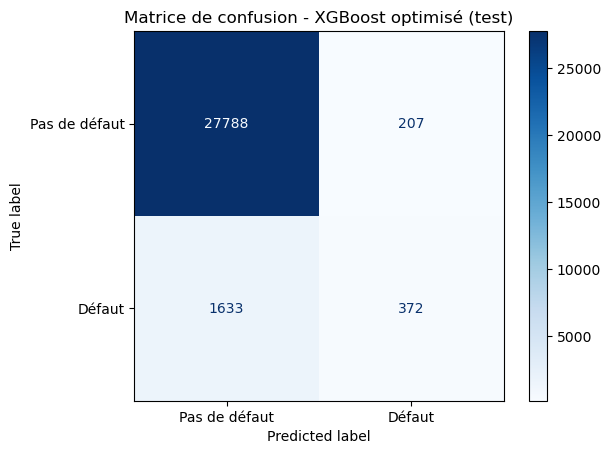

In [204]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions_test,
    display_labels=["Pas de défaut", "Défaut"],
    cmap="Blues"
)

plt.title("Matrice de confusion - XGBoost optimisé (test)")
plt.show()

## 9. Discussions et limites

### Pour conclure, nous pouvons retenir trois principaux résultats de cette étude.

* #### Tout d'abord, le nettoyage des données a joué un rôle déterminant, puisqu'il a permis d'améliorer fortement les performances de notre première régression logistique.
* #### XGBoost est l'algorithme le plus performant parmi ceux testés, avec une Average Precision de 0,428 sur notre jeu de test indépendant.
* #### Mais malgré ces bonnes performances de classement, notre modèle présente une limite importante : au seuil de 0,5, il ne détecte qu'environ 19 % des défauts réels.

### Sur les méthodes utilisées : 

* #### Le feature engineering n'a apporté qu'un gain marginal. Cela peut s'expliquer par le fait que les nouvelles variables étaient construites à partir d'informations déjà présentes dans le dataset, que XGBoost était probablement capable d'exploiter directement.
* #### L'optimisation des hyperparamètres n'a permis qu'une légère amélioration de l'Average Precision. ça suggère que notre modèle initial exploitait déjà assez bien les informations disponibles

### Limites majeures de notre modèles : 
* #### Le rappel reste très faible : seulement 18,5 % des défauts sont détectés sur le jeu de test. Mais on peut quand même nuancer ce résultat : notre modèle présente une bonne capacité à classer les emprunteurs selon leur risque, comme le montrent sa ROC-AUC de 0,872 et son Average Precision de 0,428.
* #### Le faible rappel s'explique donc en partie par notre choix d'un seuil de classification de 0,5, qui conduit à identifier relativement peu d'emprunteurs comme étant à risque.

### Ouvertures possibles : 

* #### Une piste d'amélioration serait donc de travailler sur le seuil de classification, plutôt que de chercher uniquement à améliorer les performances de l'algorithme. En effet, nous avons utilisé le seuil classique de 0,5, ce qui signifie qu'un emprunteur est considéré comme étant à risque uniquement si sa probabilité estimée de défaut dépasse 50 %. En abaissant ce seuil, nous pourrions détecter davantage de défauts et donc augmenter le rappel. Cependant, cela entraînerait également davantage de fausses alertes, ce qui pourrait diminuer la précision.
* #### L'objectif serait donc de déterminer un seuil offrant un compromis adapté entre précision et rappel, en le choisissant sur des données de validation.